In [6]:
import pandas as pd
from pathlib import Path

# Pfad zum Ordner ohne Entropie (basierend auf deinem Screenshot)
BASE_NO_ENTROPY = Path("../logs/ransomware/monitor_logs_ransomware_no_entropy")
LOG_FILES = sorted(BASE_NO_ENTROPY.glob("run_*.csv"))

results = []

for file_path in LOG_FILES:
    df = pd.read_csv(file_path)
    
    # Zählen der Operationen in der Spalte 'op'
    counts = df['op'].value_counts()
    
    reads = counts.get('READ', 0)
    writes = counts.get('WRITE', 0)
    
    # Ratio berechnen (Vermeidung von Division durch Null)
    # Ratio = Reads / Writes
    ratio = reads / writes if writes > 0 else float('inf')
    
    results.append({
        "Ransomware_Run": file_path.name,
        "Reads": reads,
        "Writes": writes,
        "Read_Write_Ratio": round(ratio, 2)
    })

# Ergebnis-Tabelle erstellen
ratio_df = pd.DataFrame(results)

print("--- Read/Write Ratio pro Ransomware-Run ---")
print(ratio_df)

# Optional: Durchschnittliche Ratio über alle Runs
if "Read_Write_Ratio" in ratio_df.columns and not ratio_df.empty:
    print(f"\nDurchschnittliche Ratio gesamt: {ratio_df['Read_Write_Ratio'].mean():.2f}")
else:
    print(f"\nKeine passenden Dateien gefunden in: {BASE_NO_ENTROPY.resolve()}")

--- Read/Write Ratio pro Ransomware-Run ---
                                 Ransomware_Run  Reads  Writes  \
0  run_ebpfangel_ransomware_20260224_140804.csv  39262   38371   
1                      run_jimmy_no_entropy.csv  20381   19786   
2                   run_quema100_no_entropy.csv  26012   25230   

   Read_Write_Ratio  
0              1.02  
1              1.03  
2              1.03  

Durchschnittliche Ratio gesamt: 1.03


In [7]:
import pandas as pd
from pathlib import Path

# Pfad zu den benignen Logs (basierend auf deiner Ordnerstruktur)
BASE_BENIGN = Path("../logs/benig/benig_no_entropy")
BENIGN_LOGS = sorted(BASE_BENIGN.glob("run*.csv")) # Filtert nach den filebench CSVs

results_benign = []

for file_path in BENIGN_LOGS:
    df = pd.read_csv(file_path)
    
    # Zählen der Operationen 'READ' und 'WRITE'
    counts = df['op'].value_counts()
    
    reads = counts.get('READ', 0)
    writes = counts.get('WRITE', 0)
    
    # Ratio berechnen
    ratio = reads / writes if writes > 0 else float('inf')
    
    results_benign.append({
        "File": file_path.name,
        "Reads": reads,
        "Writes": writes,
        "Read_Write_Ratio": round(ratio, 2)
    })

# Tabelle für benigne Anwendungen
benign_df = pd.DataFrame(results_benign)

print("--- Read/Write Ratio: Benigne Anwendungen ---")
print(benign_df)

--- Read/Write Ratio: Benigne Anwendungen ---
                      File   Reads  Writes  Read_Write_Ratio
0        run_copy_data.csv       0  103091              0.00
1  run_rw67_no_entropy.csv  942461  456398              2.06
2              run_tar.csv  110695    5561             19.91


Ransomware runs: 3
Benign runs:     3
Grid: all (w,k) with k*w <= 10.0s, theta=0.33748
CSV gespeichert: grid_eval_w_k_tracelevel.csv

BESTES (w,k) unter k*w<=10s:
interval         100ms
k                    2
TPR_trace          1.0
FPR_trace          0.0
J                  1.0
Delay_q90_sec     0.84


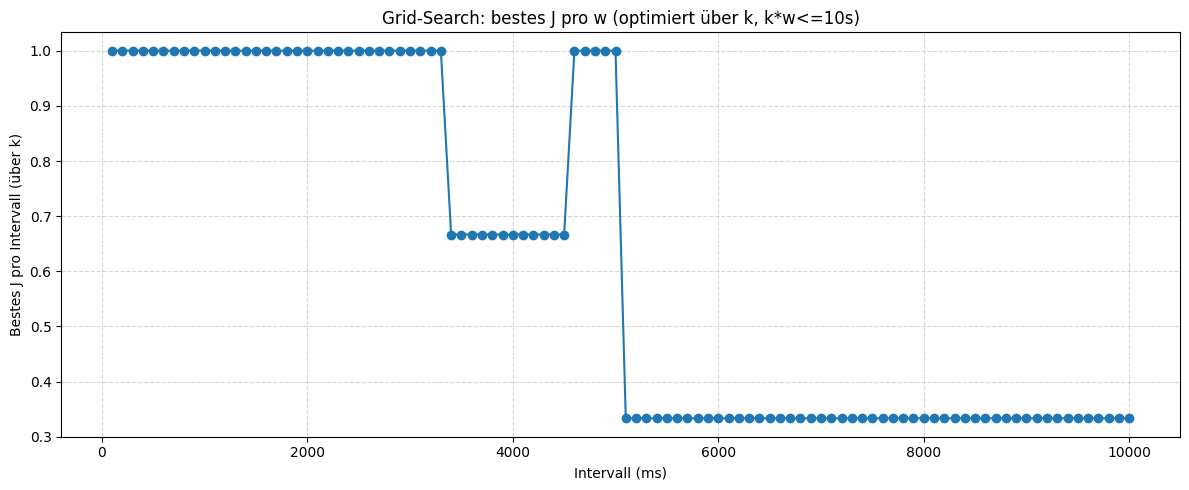

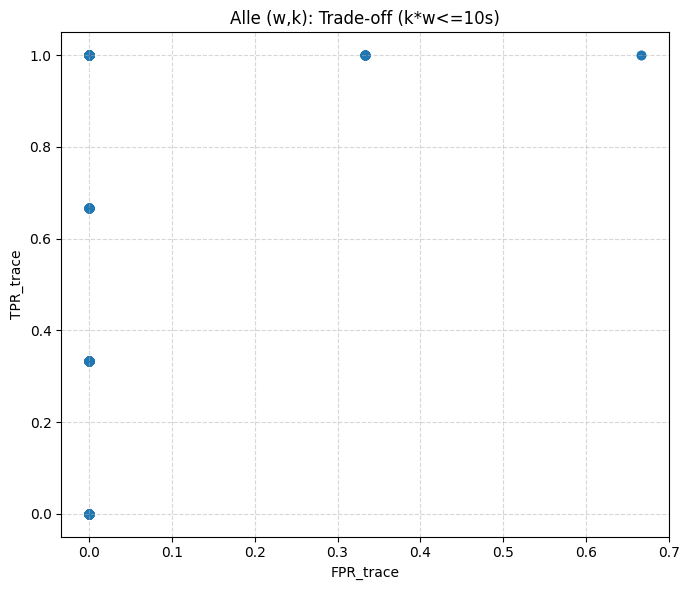

In [8]:
from __future__ import annotations

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ==============================================================================
# LOCATIONS (deine Pfade)
# ==============================================================================
BASE_NO_ENTROPY = Path("../logs/ransomware/monitor_logs_ransomware_no_entropy")
LOG_FILES = sorted(BASE_NO_ENTROPY.glob("run_*.csv"))

BASE_BENIGN = Path("../logs/benig/benig_no_entropy")
BENIGN_LOGS = sorted(BASE_BENIGN.glob("run*.csv"))


# ==============================================================================
# CONFIG
# ==============================================================================
TIME_COL = "timestamp"
OP_COL = "op"

THETA_PAPER = 0.337480  # <-- setz hier deinen Theta
DMAX_SECONDS = 10.0     # Vorgabe: max 10s bis Entscheidung/Alarm

# Intervalle testen (250ms..10s, Schritt 250ms)
INTERVALS = [f"{ms}ms" for ms in range(100, 10_000 + 1, 100)]

# Tie-break / near-optimal
J_EPS = 1e-6

# Optional: Plots
MAKE_PLOTS = True


# ==============================================================================
# HELPERS
# ==============================================================================
def load_and_prepare(path: Path, label: str) -> pd.DataFrame:
    df = pd.read_csv(path)

    if TIME_COL not in df.columns or OP_COL not in df.columns:
        raise ValueError(
            f"[{label}] CSV braucht Spalten '{TIME_COL}' und '{OP_COL}'. "
            f"Gefunden: {list(df.columns)}"
        )

    df[TIME_COL] = pd.to_datetime(df[TIME_COL], errors="raise")
    df = df.sort_values(TIME_COL).set_index(TIME_COL)

    # Falls deine ops anders heißen (z.B. "R"/"W"), diese 2 Zeilen anpassen:
    op = df[OP_COL].astype(str)
    df["reads"]  = op.str.contains("read",  case=False, na=False).astype(int)
    df["writes"] = op.str.contains("write", case=False, na=False).astype(int)

    df["label"] = label
    return df


def aggregate_windows(df: pd.DataFrame, interval: str, theta: float) -> pd.DataFrame:
    """
    Resample in nicht-overlappende Fenster. Fenster mit r+w=0 => active=False.
    suspect nur für active Fenster.
    """
    agg = df.resample(interval, origin="start")[["reads", "writes"]].sum()
    r = agg["reads"].astype(float)
    w = agg["writes"].astype(float)
    denom = r + w

    active = denom > 0
    d = pd.Series(np.nan, index=agg.index, dtype=float)
    d.loc[active] = (r.loc[active] - w.loc[active]).abs() / denom.loc[active]

    suspect = (d <= theta) & active

    return pd.DataFrame(
        {"reads": r, "writes": w, "active": active, "suspect": suspect, "d": d},
        index=agg.index,
    )


def first_alarm_times_by_k(win: pd.DataFrame, interval_td: pd.Timedelta, kmax: int):
    """
    Ein Scan -> first_alarm_end[k] für alle k=1..kmax.
    Regel:
      - active=False (r+w=0): Sequenz bricht (counter=0)
      - active=True & suspect=True: counter++
      - active=True & suspect=False: counter=0
      - Alarm für k sobald counter >= k (erster Zeitpunkt gespeichert)
    """
    idx = win.index
    active = win["active"].to_numpy()
    suspect = win["suspect"].to_numpy()

    # erster aktiver Zeitpunkt
    first_active_time = None
    for i in range(len(idx)):
        if active[i]:
            first_active_time = idx[i]
            break

    first_alarm_end = np.array([None] * (kmax + 1), dtype=object)  # index 0 unbenutzt

    if first_active_time is None:
        return None, first_alarm_end

    counter = 0
    for i, t in enumerate(idx):
        if not active[i]:
            counter = 0
            continue

        if suspect[i]:
            counter += 1
            if counter > kmax:
                counter = kmax

            # alle neu erreichten k markieren
            for k in range(1, counter + 1):
                if first_alarm_end[k] is None:
                    first_alarm_end[k] = t + interval_td  # Fenster-Endzeit
        else:
            counter = 0

    return first_active_time, first_alarm_end


def q90(x: list[float]) -> float:
    arr = np.array([v for v in x if not np.isnan(v)], dtype=float)
    if arr.size == 0:
        return np.nan
    return float(np.quantile(arr, 0.90))


# ==============================================================================
# GRID SEARCH über alle (w,k) mit k*w <= 10s
# ==============================================================================
def evaluate_all_pairs(
    ransom_dfs: list[pd.DataFrame],
    benign_dfs: list[pd.DataFrame],
    intervals: list[str],
    theta: float,
    dmax_seconds: float,
) -> pd.DataFrame:
    rows = []

    for interval in intervals:
        interval_td = pd.to_timedelta(interval)
        w_seconds = interval_td.total_seconds()
        if w_seconds <= 0:
            continue

        kmax = int(np.floor(dmax_seconds / w_seconds))
        if kmax < 1:
            kmax = 1

        # Precompute per run: first_active_time, first_alarm_end[1..kmax]
        ransom_info = []
        for df in ransom_dfs:
            win = aggregate_windows(df, interval, theta)
            fa, alarm_end = first_alarm_times_by_k(win, interval_td, kmax)
            ransom_info.append((fa, alarm_end))

        benign_info = []
        for df in benign_dfs:
            win = aggregate_windows(df, interval, theta)
            fa, alarm_end = first_alarm_times_by_k(win, interval_td, kmax)
            benign_info.append((fa, alarm_end))

        # Evaluate each k for this interval
        for k in range(1, kmax + 1):
            # --- Ransomware: Alarm innerhalb DMAX zählt als Treffer ---
            ransom_hits = []
            ransom_delays = []
            ransom_active_runs = 0

            for fa, alarm_end in ransom_info:
                if fa is None:
                    continue  # kein aktives Fenster => aus der Rate raus (NO_DECISION)
                ransom_active_runs += 1

                if alarm_end[k] is None:
                    ransom_hits.append(0)
                    ransom_delays.append(np.nan)
                    continue

                delay = (alarm_end[k] - fa).total_seconds()
                if delay <= dmax_seconds:
                    ransom_hits.append(1)
                    ransom_delays.append(delay)
                else:
                    ransom_hits.append(0)
                    ransom_delays.append(np.nan)

            tpr_trace = float(np.mean(ransom_hits)) if ransom_active_runs > 0 else np.nan
            delay_q90 = q90([d for d in ransom_delays if not np.isnan(d)])

            # --- Benign: False Alarm, wenn Alarm innerhalb DMAX passiert ---
            benign_fp = []
            benign_active_runs = 0

            for fa, alarm_end in benign_info:
                if fa is None:
                    continue
                benign_active_runs += 1

                if alarm_end[k] is None:
                    benign_fp.append(0)
                    continue

                delay = (alarm_end[k] - fa).total_seconds()
                benign_fp.append(1 if delay <= dmax_seconds else 0)

            fpr_trace = float(np.mean(benign_fp)) if benign_active_runs > 0 else np.nan

            J = (tpr_trace - fpr_trace) if (not np.isnan(tpr_trace) and not np.isnan(fpr_trace)) else np.nan

            rows.append(
                {
                    "interval": interval,
                    "interval_ms": int(w_seconds * 1000),
                    "k": k,
                    "kmax_for_interval": kmax,
                    "TPR_trace": tpr_trace,
                    "FPR_trace": fpr_trace,
                    "J": J,
                    "Delay_q90_sec": delay_q90,
                    "active_ransom_runs": ransom_active_runs,
                    "active_benign_runs": benign_active_runs,
                }
            )

    return pd.DataFrame(rows)


def pick_best_pair(eval_df: pd.DataFrame) -> pd.Series | None:
    tmp = eval_df.dropna(subset=["J"]).copy()
    if tmp.empty:
        return None

    j_max = float(tmp["J"].max())
    cand = tmp[tmp["J"] >= (j_max - J_EPS)].copy()

    # Tie-breaker:
    # 1) kleineres Delay_q90 (wenn NaN -> inf)
    # 2) kleineres interval_ms
    # 3) kleineres k
    cand["Delay_q90_fill"] = cand["Delay_q90_sec"].fillna(np.inf)
    cand = cand.sort_values(["Delay_q90_fill", "interval_ms", "k"], ascending=[True, True, True])
    return cand.iloc[0]


# ==============================================================================
# MAIN
# ==============================================================================
def main():
    if not LOG_FILES:
        raise RuntimeError(f"Keine Ransomware-Logs gefunden in: {BASE_NO_ENTROPY}")
    if not BENIGN_LOGS:
        raise RuntimeError(f"Keine Benign-Logs gefunden in: {BASE_BENIGN}")

    print(f"Ransomware runs: {len(LOG_FILES)}")
    print(f"Benign runs:     {len(BENIGN_LOGS)}")
    print(f"Grid: all (w,k) with k*w <= {DMAX_SECONDS}s, theta={THETA_PAPER}")

    ransom_dfs = [load_and_prepare(p, f"R_{p.stem}") for p in LOG_FILES]
    benign_dfs = [load_and_prepare(p, f"B_{p.stem}") for p in BENIGN_LOGS]

    eval_df = evaluate_all_pairs(
        ransom_dfs=ransom_dfs,
        benign_dfs=benign_dfs,
        intervals=INTERVALS,
        theta=THETA_PAPER,
        dmax_seconds=DMAX_SECONDS,
    )

    out_csv = "grid_eval_w_k_tracelevel.csv"
    eval_df.to_csv(out_csv, index=False)
    print(f"CSV gespeichert: {out_csv}")

    best = pick_best_pair(eval_df)
    if best is None:
        print("Kein bestes (w,k) gefunden (zu viele NaNs / keine aktiven Fenster?).")
        return

    print("\nBESTES (w,k) unter k*w<=10s:")
    print(best[["interval", "k", "TPR_trace", "FPR_trace", "J", "Delay_q90_sec"]].to_string())

    if MAKE_PLOTS:
        # Plot: pro Intervall bestes k (max J)
        tmp = eval_df.dropna(subset=["J"]).copy()
        best_per_w = tmp.sort_values(["interval_ms", "J"], ascending=[True, False]).groupby("interval_ms", as_index=False).first()

        plt.figure(figsize=(12, 5))
        plt.plot(best_per_w["interval_ms"], best_per_w["J"], marker="o")
        plt.xlabel("Intervall (ms)")
        plt.ylabel("Bestes J pro Intervall (über k)")
        plt.title("Grid-Search: bestes J pro w (optimiert über k, k*w<=10s)")
        plt.grid(True, linestyle="--", alpha=0.5)
        plt.tight_layout()
        plt.show()

        # Plot: alle Kandidaten (FPR vs TPR), farbe nicht gesetzt (default)
        plt.figure(figsize=(7, 6))
        plt.scatter(tmp["FPR_trace"], tmp["TPR_trace"])
        plt.xlabel("FPR_trace")
        plt.ylabel("TPR_trace")
        plt.title("Alle (w,k): Trade-off (k*w<=10s)")
        plt.grid(True, linestyle="--", alpha=0.5)
        plt.tight_layout()
        plt.show()


if __name__ == "__main__":
    main()

interval    TPR_q    FPR_q      J_q  TPR_min  FPR_max
   250ms 0.708682 0.031254 0.677429 0.652841 0.043933
   500ms 0.802927 0.032760 0.770167 0.764511 0.043478
   750ms 0.847231 0.033518 0.813713 0.817164 0.043915
  1000ms 0.877454 0.034553 0.842901 0.854305 0.045075
  1250ms 0.904745 0.031249 0.873496 0.886128 0.043750
  1500ms 0.893515 0.033234 0.860281 0.875622 0.042607
  1750ms 0.909218 0.034410 0.874809 0.893064 0.043732
  2000ms 0.918781 0.033948 0.884833 0.904290 0.043333
  2250ms 0.924627 0.035408 0.889219 0.910448 0.044944
  2500ms 0.931381 0.035898 0.895483 0.921488 0.045643
  2750ms 0.934545 0.036110 0.898435 0.922727 0.045872
  3000ms 0.935619 0.035346 0.900273 0.925743 0.045000
  3250ms 0.947312 0.038054 0.909258 0.940860 0.048649
  3500ms 0.950528 0.032598 0.917930 0.948276 0.040698
  3750ms 0.946891 0.034625 0.912266 0.938272 0.043750
  4000ms 0.955246 0.036776 0.918469 0.947368 0.046667
  4250ms 0.952428 0.033841 0.918587 0.944056 0.042553
  4500ms 0.962698 0.035510 0

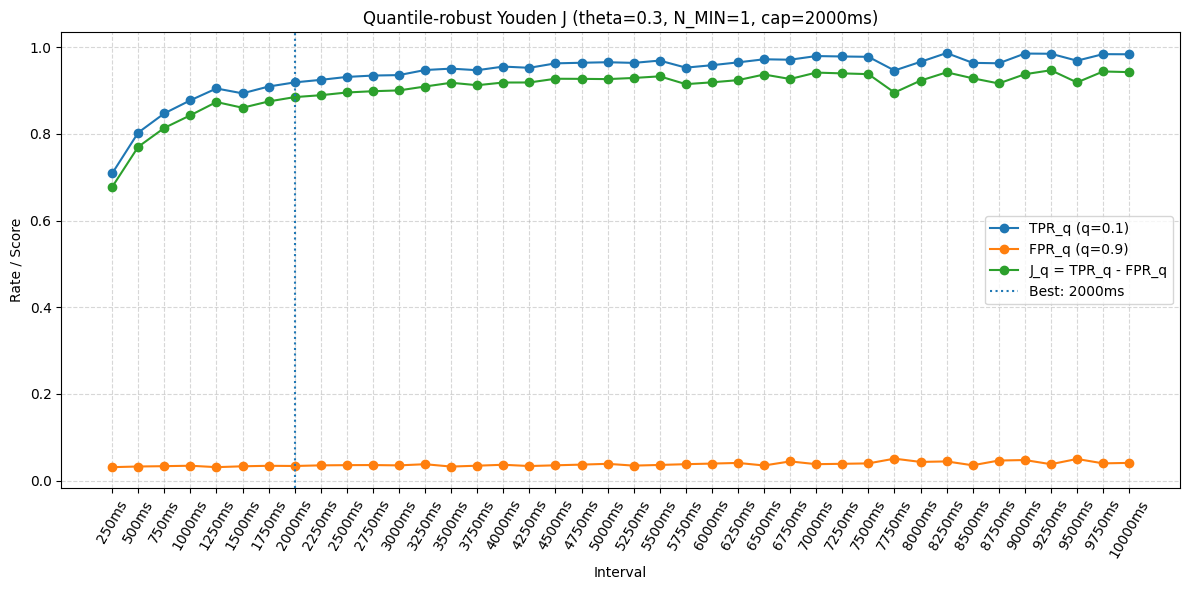

In [ ]:
from __future__ import annotations
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==============================================================================
# CONFIG
# ==============================================================================
TIME_COL = "timestamp"
OP_COL = "op"

THETA = 0.3
N_MIN = 1

# Robustheit als Quantile (statt min/max)
RANSOM_Q = 0.10   # 10%-Quantil => "meiste" Ransomware, aber nicht der härteste Ausreißer
BENIGN_Q = 0.90   # 90%-Quantil => "schlimme" Benign, aber nicht absolut max

# Fenster (250ms..10s)
INTERVALS = [f"{ms}ms" for ms in range(250, 10_000 + 1, 250)]

# Wichtig: du willst kleine Fenster => setz optional ein hartes Latenz-Cap
W_MAX_MS: int | None = 2000   # z.B. 2000ms; wenn du kein Cap willst: None

# "nahezu gleich gut": nimm kleinste Fenstergröße innerhalb dieser Toleranz
J_TOL = 0.005  # je größer, desto mehr bevorzugst du kleine w

# ==============================================================================
# DATEIEN (deine Patterns)
# ==============================================================================
BASE_NO_ENTROPY = Path("../logs/ransomware/monitor_logs_ransomware_no_entropy")
RANSOM_LOGS = sorted(BASE_NO_ENTROPY.glob("run_*.csv"))

BASE_BENIGN = Path("../logs/old_data/tmp/old")
BENIGN_LOGS = sorted(BASE_BENIGN.glob("filebench_*.csv"))

# ==============================================================================
# HELPERS
# ==============================================================================
def short_name(p: Path | str) -> str:
    return Path(p).stem

def interval_to_ms(interval: str) -> int:
    return int(pd.to_timedelta(interval).total_seconds() * 1000)

def load_and_prepare(path: Path, label: str) -> pd.DataFrame:
    df = pd.read_csv(path)
    if TIME_COL not in df.columns or OP_COL not in df.columns:
        raise ValueError(f"[{label}] Missing '{TIME_COL}' or '{OP_COL}'. Found: {list(df.columns)}")

    df[TIME_COL] = pd.to_datetime(df[TIME_COL], errors="raise")
    df = df.sort_values(TIME_COL).set_index(TIME_COL)

    op = df[OP_COL].astype(str)
    df["reads"]  = op.str.contains("read",  case=False, na=False).astype(int)
    df["writes"] = op.str.contains("write", case=False, na=False).astype(int)
    df["label"] = label
    return df

def d_series_per_window(df: pd.DataFrame, interval: str, n_min: int = 1) -> np.ndarray:
    # origin='epoch' => gleiche Fenstergrenzen für alle Traces
    agg = df.resample(interval, origin="epoch")[["reads", "writes"]].sum()
    N = agg["reads"] + agg["writes"]
    agg = agg[N >= n_min]
    if agg.empty:
        return np.array([])
    r = agg["reads"].to_numpy(float)
    w = agg["writes"].to_numpy(float)
    return np.abs(r - w) / (r + w)

def rate_below_theta(d: np.ndarray, theta: float) -> float:
    if d.size == 0:
        return np.nan
    return float(np.mean(d <= theta))

# ==============================================================================
# EVAL (Quantil-robust)
# ==============================================================================
def evaluate(intervals: list[str], ransom_dfs, ransom_names, benign_dfs, benign_names) -> pd.DataFrame:
    rows = []
    for interval in intervals:
        tprs = []
        for df in ransom_dfs:
            d = d_series_per_window(df, interval, n_min=N_MIN)
            tprs.append(rate_below_theta(d, THETA))
        tprs = np.array(tprs, dtype=float)

        fprs = []
        for df in benign_dfs:
            d = d_series_per_window(df, interval, n_min=N_MIN)
            fprs.append(rate_below_theta(d, THETA))
        fprs = np.array(fprs, dtype=float)

        # Quantil-robust (statt min/max)
        tpr_q = np.nanquantile(tprs, RANSOM_Q) if np.any(~np.isnan(tprs)) else np.nan
        fpr_q = np.nanquantile(fprs, BENIGN_Q) if np.any(~np.isnan(fprs)) else np.nan
        J_q = (tpr_q - fpr_q) if (not np.isnan(tpr_q) and not np.isnan(fpr_q)) else np.nan

        # Debug: welche Datei liegt am Quantil ungefähr? (optional hilfreich)
        worst_ransom = ransom_names[int(np.nanargmin(tprs))] if np.any(~np.isnan(tprs)) else None
        worst_benign = benign_names[int(np.nanargmax(fprs))] if np.any(~np.isnan(fprs)) else None

        rows.append({
            "interval": interval,
            "interval_ms": interval_to_ms(interval),

            "TPR_q": tpr_q,
            "FPR_q": fpr_q,
            "J_q": J_q,

            "TPR_min": np.nanmin(tprs) if np.any(~np.isnan(tprs)) else np.nan,
            "FPR_max": np.nanmax(fprs) if np.any(~np.isnan(fprs)) else np.nan,

            "worst_ransom(min)": worst_ransom,
            "worst_benign(max)": worst_benign,
        })
    return pd.DataFrame(rows)

def pick_smallest_near_best(eval_df: pd.DataFrame) -> pd.Series | None:
    tmp = eval_df.dropna(subset=["J_q", "interval_ms"]).copy()
    if W_MAX_MS is not None:
        tmp = tmp[tmp["interval_ms"] <= W_MAX_MS]
    if tmp.empty:
        return None

    bestJ = float(tmp["J_q"].max())
    candidates = tmp[tmp["J_q"] >= (bestJ - J_TOL)].copy()
    # wichtig: du willst kleines Fenster => kleinste ms gewinnt
    return candidates.sort_values("interval_ms", ascending=True).iloc[0]

# ==============================================================================
# MAIN
# ==============================================================================
def main():
    if not RANSOM_LOGS:
        raise FileNotFoundError(f"No ransom logs in {BASE_NO_ENTROPY.resolve()}")
    if not BENIGN_LOGS:
        raise FileNotFoundError(f"No benign logs in {BASE_BENIGN.resolve()}")

    ransom_dfs, ransom_names = [], []
    for p in RANSOM_LOGS:
        name = f"Ransom_{short_name(p)}"
        ransom_dfs.append(load_and_prepare(p, name))
        ransom_names.append(name)

    benign_dfs, benign_names = [], []
    for p in BENIGN_LOGS:
        name = f"Benign_{short_name(p)}"
        benign_dfs.append(load_and_prepare(p, name))
        benign_names.append(name)

    eval_df = evaluate(INTERVALS, ransom_dfs, ransom_names, benign_dfs, benign_names)
    best = pick_smallest_near_best(eval_df)

    print(eval_df[["interval","TPR_q","FPR_q","J_q","TPR_min","FPR_max"]].to_string(index=False))

    if best is not None:
        print("\nBEST (Quantil-robust + kleinste Fenstergröße nahe Bestem):")
        print(best[["interval","interval_ms","TPR_q","FPR_q","J_q","TPR_min","FPR_max"]].to_string())
    else:
        print("\nKein bestes Fenster gefunden (alles NaN oder nach Cap leer).")

    eval_df.to_csv("eval_intervals_quantile_robust.csv", index=False)

    # Plot
    plt.figure(figsize=(12, 6))
    plt.plot(eval_df["interval"], eval_df["TPR_q"], marker="o", label=f"TPR_q (q={RANSOM_Q})")
    plt.plot(eval_df["interval"], eval_df["FPR_q"], marker="o", label=f"FPR_q (q={BENIGN_Q})")
    plt.plot(eval_df["interval"], eval_df["J_q"], marker="o", label="J_q = TPR_q - FPR_q")
    if best is not None:
        plt.axvline(best["interval"], linestyle=":", label=f"Best: {best['interval']}")
    cap_txt = f", cap={W_MAX_MS}ms" if W_MAX_MS is not None else ""
    plt.title(f"Quantile-robust Youden J (theta={THETA}, N_MIN={N_MIN}{cap_txt})")
    plt.ylabel("Rate / Score")
    plt.xlabel("Interval")
    plt.xticks(rotation=60)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    main()